# DC4 source catalog: detector-energy count audit

Compare the **saved historical 0.30-tail parallel-chunks catalog snapshot** with the DC4 source event FITS in each of the ten measured-energy (`Em`) bins. This is a detector-space count comparison after response folding, not a comparison of incident spectra or a new NGC 4151 fit.

The snapshot predates restoration of the original lower-tail NGC 4151 model in the YAML. Its NGC model counts remain from the prior 0.30-tail catalog; regenerate the generator snapshot to audit the edited catalog. The saved generator snapshot contains one folded count spectrum and one source-event spectrum for each of 71 entries under the NGC 4151 GTI. It saves the `Em` projection of the detector histogram; `Phi` and `PsiChi` have been summed. Reading it avoids folding the catalog again. The snapshot's NGC 4151 FITS row is **modified 0.30-tail data**. For a fair comparison with the original full mock, this notebook selects the **original** NGC 4151 event FITS using the same 60°/Earth-occultation GTI. The catalog NGC 4151 model remains the 0.30-tail injection, so we report that difference explicitly.

In [1]:
from pathlib import Path
import json
import sys

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from histpy import Histogram
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from cosipy.event_selection import GoodTimeInterval
from cosipy.spacecraftfile import SpacecraftHistory

# Locate the tutorial when VS Code launches the kernel from the repository root.
notebook_dir = Path.cwd().resolve()
if not (notebook_dir / "source_catalog_DC4_lightcurve_comparison.json").is_file():
    candidates = [p / "docs/tutorials/spectral_fits/continuum_fit/AGN"
                  for p in (notebook_dir, *notebook_dir.parents)]
    notebook_dir = next((p for p in candidates
                         if (p / "source_catalog_DC4_lightcurve_comparison.json").is_file()), None)
if notebook_dir is None:
    raise FileNotFoundError("Could not locate the AGN tutorial directory")

cache_path = notebook_dir / "source_catalog_DC4_lightcurve_comparison.json"
dc4_root = Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files"
original_mock_path = dc4_root / "Mock_Data/Mock_Data_Cut/dc4_mock_dataset_3months_unbinned_data_filtered_with_SAAcut_time_ordered_ngc4151_in_fov_binned.hdf5"
background_path = dc4_root / "Background/Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_withSAAbck_NGC4151_60deg_fov_cut.hdf5"
ngc_original_fits_path = dc4_root / "DC4_Sources/DC4/NGC_4151_3months_unbinned_data_filtered_with_SAAcut.fits.gz"
orientation_path = dc4_root / "DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori"
for path in (cache_path, original_mock_path, background_path,
             ngc_original_fits_path, orientation_path):
    if not path.is_file():
        raise FileNotFoundError(path)
print("Comparison snapshot:", cache_path)
print("Original mock:", original_mock_path)


10:56:12 WARNING   The naima package is not available. Models    functions.py:43
                  that depend on it will not be available                       
         WARNING   The GSL library or the pygsl wrapper cannot   functions.py:65
                  be loaded. Models that depend on it will not                  
                  be available.                                                 
         WARNING   The ebltable package is not available.       absorption.py:33
                  Models that depend on it will not be                          
                  available                                                     
10:56:13 INFO      Starting 3ML!                                  __init__.py:44
         WARNING   WARNINGs here are NOT errors                   __init__.py:45
         WARNING   but are inform you about optional packages     __init__.py:46
                  that can be installed                                         
         WARNING    to disab

In [2]:
snapshot = json.loads(cache_path.read_text())
if snapshot.get("schema") != "dc4-lightcurve-count-comparison-v1":
    raise ValueError("Unsupported comparison snapshot")
if Path(snapshot["provenance"]["orientation"]).name != orientation_path.name:
    raise ValueError("Snapshot and selected orientation differ")
if Path(snapshot["provenance"]["binning"]).name != "agn.yaml":
    raise ValueError("Expected the AGN detector binning")
rows = {r["source"]: r for r in snapshot["records"]
        if r["selection"] == "NGC4151_GTI"}
if len(rows) != 71 or "ngc4151" not in rows:
    raise ValueError("Expected 71 unique sources for the NGC 4151 GTI")
assert len([r for r in snapshot["records"] if r["selection"] == "NGC4151_GTI"]) == 71
edges = np.asarray(snapshot["energy_edges_keV"], dtype=float)
if len(edges) != 11 or not np.all(np.diff(edges) > 0):
    raise ValueError("Expected ten ordered detector-energy bins")
parallel_label = "Parallel chunks + LC response"
for source, row in rows.items():
    for label in ("FITS", parallel_label):
        values = np.asarray(row["counts"][label], dtype=float)
        if values.shape != (10,) or np.any(~np.isfinite(values)) or np.any(values < 0):
            raise ValueError(f"Invalid {label} counts for {source}")
print(f"Loaded {len(rows)} sources; snapshot made {snapshot['created_utc']}")
print("Energy edges (keV):", edges)


Loaded 71 sources; snapshot made 2026-09-18T04:01:43.923058+00:00
Energy edges (keV): [  100.      158.489   251.189   398.107   630.957  1000.     1584.89
  2511.89   3981.07   6309.57  10000.   ]


## Match the original NGC 4151 injection to the original mock

The generator's cached NGC 4151 source counts were taken from the modified 0.30-tail HDF5. Its row cannot serve as the observed NGC 4151 spectrum for the original mock. We select original FITS events in the notebook using the **same** pointing cut that generated the snapshot. The time intervals use `[start, stop)` membership. We retain only events within the measured-energy and Compton-angle histogram ranges.

In [4]:
# Position from the catalog's NGC 4151 point source (Galactic coordinates).
ngc_coord = SkyCoord(l=155.077404 * u.deg, b=75.06317 * u.deg,
                     frame="galactic")
history = SpacecraftHistory.open(orientation_path)
ngc_gti = GoodTimeInterval.from_pointing_cut(
    ngc_coord, history, 60.0 * u.deg, earth_occ=True,
)
starts = np.asarray(ngc_gti.tstart_list.unix, dtype=float)
stops = np.asarray(ngc_gti.tstop_list.unix, dtype=float)
if len(starts) == 0 or np.any(stops <= starts):
    raise ValueError("Empty or invalid NGC 4151 GTI")
original_ngc_em = np.zeros(10, dtype=np.int64)
with fits.open(ngc_original_fits_path, memmap=False) as hdul:
    events = hdul[1].data
    for offset in range(0, len(events), 250_000):
        block = events[offset:offset + 250_000]
        times = np.asarray(block["TimeTags"], dtype=float)
        interval = np.searchsorted(starts, times, side="right") - 1
        energies = np.asarray(block["Energies"], dtype=float)
        phi_degrees = np.rad2deg(np.asarray(block["Phi"], dtype=float))
        selected = ((interval >= 0)
                    & (times < stops[np.maximum(interval, 0)])
                    & (energies >= edges[0]) & (energies < edges[-1])
                    & (phi_degrees >= 0) & (phi_degrees < 180))
        original_ngc_em += np.histogram(energies[selected], bins=edges)[0]
modified_ngc_em = np.asarray(rows["ngc4151"]["counts"]["FITS"], dtype=float)
print("Original NGC 4151 GTI counts:", original_ngc_em.sum())
print("Modified 0.30-tail cached counts:", modified_ngc_em.sum())
print("Modified minus original, by Em bin:",
      np.round(modified_ngc_em - original_ngc_em, 2))


Original NGC 4151 GTI counts: 54915
Modified 0.30-tail cached counts: 76103.39876128687
Modified minus original, by Em bin: [8.59215e+03 8.90845e+03 2.98299e+03 5.29610e+02 1.37220e+02 3.30400e+01
 3.87000e+00 9.90000e-01 8.00000e-02 0.00000e+00]


## Check source-event and full-mock count closure

This check is important before interpreting residuals. The sum of original source events and instrumental background should reproduce the original full mock under the same GTI and detector binning. We compare the snapshot source-event sum after replacing only the modified NGC 4151 row. The small possible difference from histogram edge handling is printed rather than hidden.

In [6]:
def em_counts(path):
    histogram = Histogram.open(path).project("Em")
    measured_edges = histogram.axes["Em"].edges.to_value(u.keV)
    np.testing.assert_allclose(measured_edges, edges, rtol=0, atol=1e-6)
    values = np.asarray(histogram.to_dense(copy=False).contents, dtype=float)
    if values.shape != (10,) or np.any(~np.isfinite(values)):
        raise ValueError(f"Unexpected detector histogram: {path}")
    return values

mock_em = em_counts(original_mock_path)
background_em = em_counts(background_path)
fits_by_source = {s: np.asarray(r["counts"]["FITS"], dtype=float).copy()
                  for s, r in rows.items()}
fits_by_source["ngc4151"] = original_ngc_em.astype(float)
model_by_source = {s: np.asarray(r["counts"][parallel_label], dtype=float).copy()
                   for s, r in rows.items()}
fits_sky_em = np.sum(list(fits_by_source.values()), axis=0)
model_sky_em = np.sum(list(model_by_source.values()), axis=0)
observed_sky_em = mock_em - background_em
closure_em = observed_sky_em - fits_sky_em
closure = pd.DataFrame({
    "Em low (keV)": edges[:-1], "Em high (keV)": edges[1:],
    "full mock": mock_em, "background FITS": background_em,
    "sum original source FITS": fits_sky_em,
    "mock - (background + source FITS)": closure_em,
})
display(closure)
print("Total full mock:", mock_em.sum())
print("Total background:", background_em.sum())
print("Total original source FITS:", fits_sky_em.sum())
print("Total closure difference:", closure_em.sum())
if np.max(np.abs(closure_em)) > 5:
    raise RuntimeError("Full mock does not close against the selected source FITS plus background")


 Em low (keV)  Em high (keV)  full mock  background FITS  sum original source FITS  mock - (background + source FITS)
      100.000        158.489  3524473.0        3371214.0                  153259.0                                0.0
      158.489        251.189  7122930.0        6783193.0                  339736.0                                1.0
      251.189        398.107  5508031.0        5215451.0                  292580.0                                0.0
      398.107        630.957  3717257.0        3540103.0                  177154.0                                0.0
      630.957       1000.000  2402707.0        2337742.0                   64965.0                                0.0
     1000.000       1584.890  1909431.0        1871494.0                   37937.0                                0.0
     1584.890       2511.890  1289159.0        1267750.0                   21409.0                                0.0
     2511.890       3981.070   552208.0         547020.0

## Per-source count discrepancies

These are counts in `Em` after folding each fixed source model through its GTI response. The first table ranks **absolute** count differences, which matter for the full mock; the second ranks **fractional** differences for sources with at least 1,000 observed counts. The `model / FITS` ratio uses the original NGC 4151 FITS for that one row. A single ratio cannot reveal energy-dependent errors, so the subsequent figures and tables retain all ten bins.

In [8]:
source_rows = []
for source in sorted(rows):
    observed = fits_by_source[source]
    predicted = model_by_source[source]
    source_rows.append({
        "source": source,
        "FITS counts": observed.sum(),
        "model counts": predicted.sum(),
        "model - FITS": predicted.sum() - observed.sum(),
        "model / FITS": predicted.sum() / observed.sum() if observed.sum() > 0 else np.nan,
        "100-398 keV model - FITS": (predicted[:3] - observed[:3]).sum(),
        "398-10000 keV model - FITS": (predicted[3:] - observed[3:]).sum(),
    })
source_table = pd.DataFrame(source_rows)
absolute_rank = source_table.iloc[source_table["model - FITS"].abs().argsort()[::-1]]
ratio_rank = source_table.loc[source_table["FITS counts"] >= 1000].copy()
ratio_rank = ratio_rank.iloc[(ratio_rank["model / FITS"] - 1).abs().argsort()[::-1]]
print("Largest absolute differences:")
display(absolute_rank.head(15).style.format(precision=2))
print("Largest fractional differences among sources with >= 1,000 FITS counts:")
display(ratio_rank.head(15).style.format(precision=3))


Largest absolute differences:
                  source  FITS counts  model counts  model - FITS  model / FITS  100-398 keV model - FITS  398-10000 keV model - FITS
                    crab     599435.0 637409.024654  37974.024654      1.063350              35823.726675                 2150.297980
                 ngc4151      54915.0  76103.398761  21188.398761      1.385840              20483.581760                  704.817002
              maxi_j1820      45875.0  55713.291974   9838.291974      1.214459               8600.515438                 1237.776536
      four_c_21p35_flare     165892.0 175593.503859   9701.503859      1.058481               9902.436850                 -200.932991
            four_c_71p07      36917.0  38945.301921   2028.301921      1.054942               1582.855027                  445.446895
positrons_thin_disk_cont      42739.0  44718.819449   1979.819449      1.046323                336.838731                 1642.980719
            vela_snr_511      11

In [9]:
# The high-impact sources receive a per-bin count and ratio table.
focus = [s for s in ["ngc4151", "crab", "maxi_j1820", "four_c_21p35_flare",
                     "three_c_454p3_high", "cyg_x1_hard"] if s in rows]
for source in focus:
    observed = fits_by_source[source]
    predicted = model_by_source[source]
    detail = pd.DataFrame({
        "Em low (keV)": edges[:-1], "Em high (keV)": edges[1:],
        "FITS": observed, "model": predicted,
        "model - FITS": predicted - observed,
        "model / FITS": np.divide(predicted, observed, out=np.full(10, np.nan), where=observed > 0),
    })
    print(source)
    display(detail.style.format(precision=2))

# Export every source/bin pair for follow-up checks in a spreadsheet or script.
per_bin_rows = []
for source in sorted(rows):
    for i in range(10):
        observed = float(fits_by_source[source][i])
        predicted = float(model_by_source[source][i])
        per_bin_rows.append({
            "source": source, "Em low (keV)": edges[i], "Em high (keV)": edges[i+1],
            "original FITS counts": observed, "catalog predicted counts": predicted,
            "model - FITS": predicted - observed,
            "model / FITS": predicted / observed if observed > 0 else np.nan,
        })
per_bin_table = pd.DataFrame(per_bin_rows)
per_bin_path = notebook_dir / "plots/DC4_source_catalog_detector_energy_per_source.csv"
per_bin_table.to_csv(per_bin_path, index=False)
print("Saved all 710 source/bin comparisons:", per_bin_path)


ngc4151
 Em low (keV)  Em high (keV)    FITS        model  model - FITS  model / FITS
      100.000        158.489 13459.0 22051.146306   8592.146306      1.638394
      158.489        251.189 24038.0 32946.447150   8908.447150      1.370599
      251.189        398.107 13373.0 16355.988304   2982.988304      1.223061
      398.107        630.957  3514.0  4043.608349    529.608349      1.150714
      630.957       1000.000   494.0   631.222687    137.222687      1.277779
     1000.000       1584.890    33.0    66.040109     33.040109      2.001215
     1584.890       2511.890     4.0     7.870954      3.870954      1.967738
     2511.890       3981.070     0.0     0.990074      0.990074           NaN
     3981.070       6309.570     0.0     0.082673      0.082673           NaN
     6309.570      10000.000     0.0     0.002155      0.002155           NaN
crab
 Em low (keV)  Em high (keV)     FITS         model  model - FITS  model / FITS
      100.000        158.489  86054.0  99483.1275

## Where in measured energy do the errors accumulate?

The historical 0.30-tail catalog prediction below is **before fitting**: all 71 sources use their injected catalog parameters, and the instrumental background uses its observed template normalization. Its NGC 4151 source model is the modified 0.30-tail model. We also show a diagnostic version that substitutes the *observed original* NGC 4151 source counts, isolating the remaining catalog/source discrepancies. This substitution is a count diagnostic, **not** a physical refit or a replacement catalog.

In [11]:
model_total_em = background_em + model_sky_em
model_other_em = model_sky_em - model_by_source["ngc4151"]
original_ngc_matched_em = background_em + model_other_em + original_ngc_em
energy_table = pd.DataFrame({
    "Em low (keV)": edges[:-1], "Em high (keV)": edges[1:],
    "mock counts": mock_em, "injected catalog + background": model_total_em,
    "catalog - mock": model_total_em - mock_em,
    "catalog / mock": model_total_em / mock_em,
    "other-source model - other-source FITS":
        model_other_em - (fits_sky_em - original_ngc_em),
    "original-NGC-matched model - mock": original_ngc_matched_em - mock_em,
})
display(energy_table.style.format(precision=3))
print("Catalog minus mock total:", float((model_total_em - mock_em).sum()))
print("After replacing catalog NGC with original source counts:",
      float((original_ngc_matched_em - mock_em).sum()))
print("Non-NGC catalog discrepancy below 398 keV:",
      float((model_other_em[:3] - (fits_sky_em[:3] - original_ngc_em[:3])).sum()))


 Em low (keV)  Em high (keV)  mock counts  injected catalog + background  catalog - mock  catalog / mock  other-source model - other-source FITS  original-NGC-matched model - mock
      100.000        158.489    3524473.0                   3.554513e+06    30039.715100        1.008523                            21447.568793                       21447.568793
      158.489        251.189    7122930.0                   7.158465e+06    35534.743620        1.004989                            26627.296470                       26626.296470
      251.189        398.107    5508031.0                   5.522290e+06    14258.689283        1.002589                            11275.700979                       11275.700979
      398.107        630.957    3717257.0                   3.724273e+06     7016.042874        1.001887                             6486.434525                        6486.434525
      630.957       1000.000    2402707.0                   2.404069e+06     1362.323834        1.00


WARNING UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/DC4_source_catalog_detector_energy_total_residuals.png


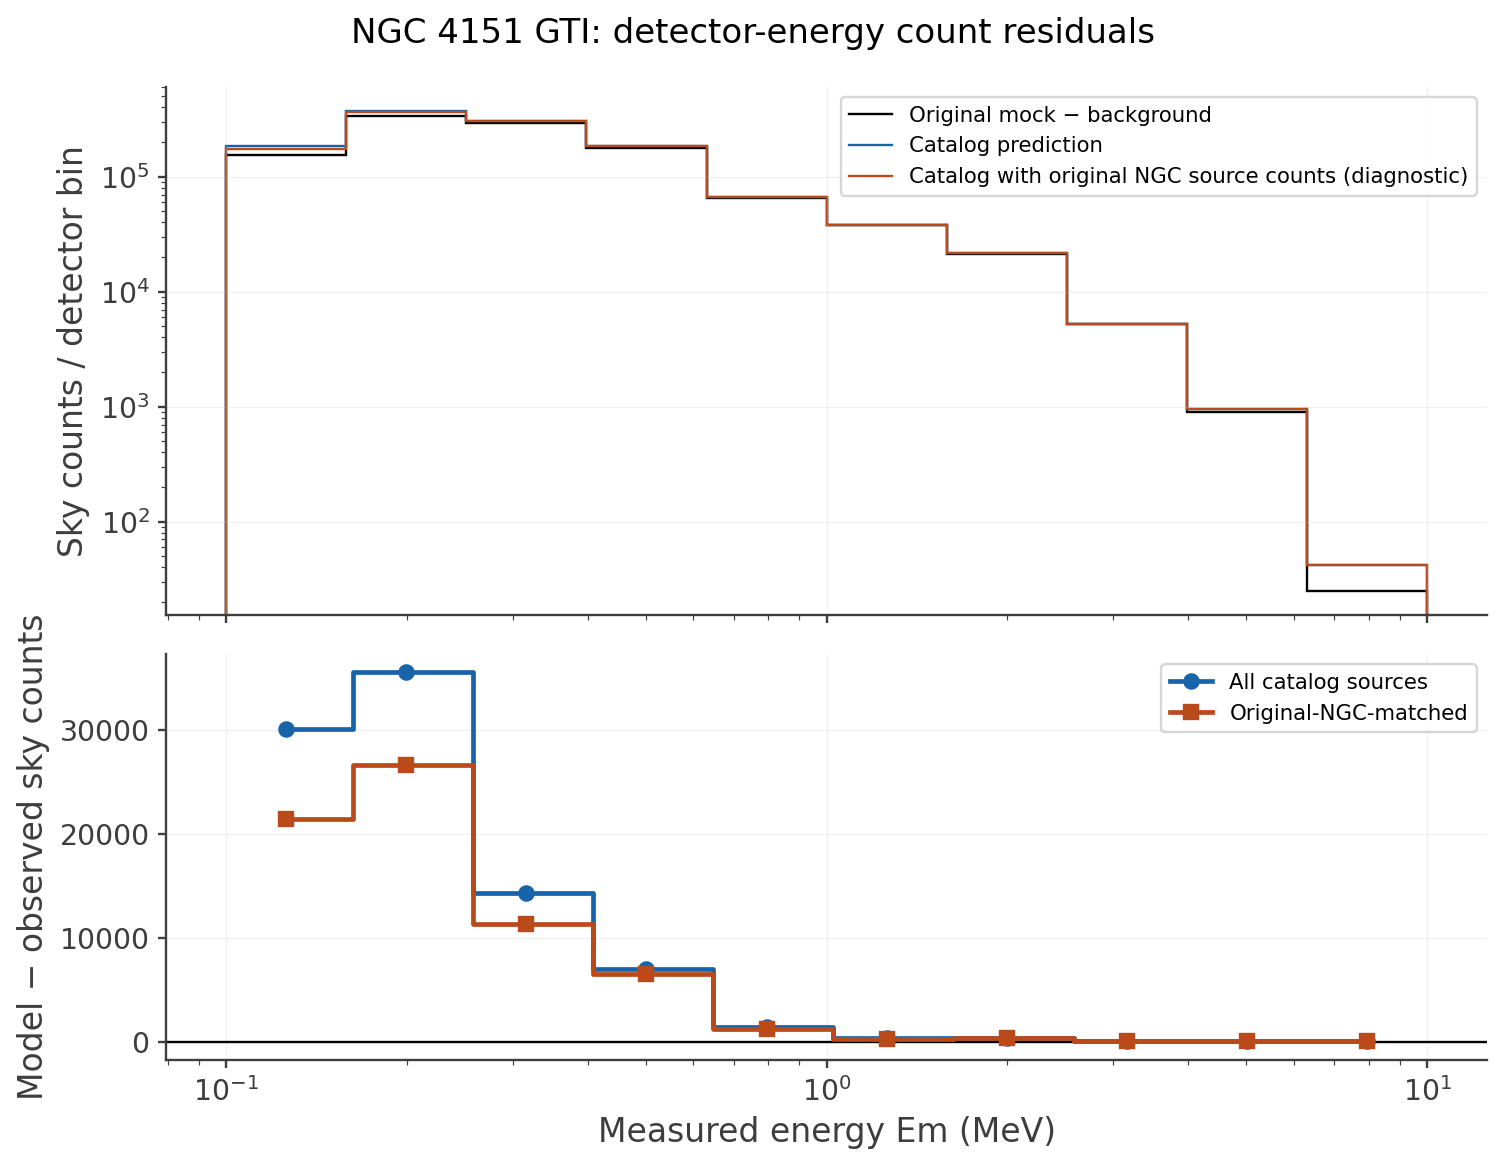

In [12]:
# Visualize the broad-bin residuals on a common, measured-energy axis.
centers = np.sqrt(edges[:-1] * edges[1:]) / 1000.0  # MeV
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True,
                         gridspec_kw={"height_ratios": [1.3, 1]})
axes[0].stairs(observed_sky_em, edges / 1000, color="black", label="Original mock − background")
axes[0].stairs(model_sky_em, edges / 1000, color="#1764aa", label="Catalog prediction")
axes[0].stairs(model_other_em + original_ngc_em, edges / 1000, color="#ba4a19",
               label="Catalog with original NGC source counts (diagnostic)")
axes[0].set_yscale("log")
axes[0].set_ylabel("Sky counts / detector bin")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.25)
axes[1].axhline(0, color="black", lw=1)
axes[1].step(centers, model_sky_em - observed_sky_em, where="mid", color="#1764aa",
             marker="o", label="All catalog sources")
axes[1].step(centers, model_other_em + original_ngc_em - observed_sky_em,
             where="mid", color="#ba4a19", marker="s", label="Original-NGC-matched")
axes[1].set_xscale("log")
axes[1].set_xlabel("Measured energy Em (MeV)")
axes[1].set_ylabel("Model − observed sky counts")
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=9)
fig.suptitle("NGC 4151 GTI: detector-energy count residuals")
fig.tight_layout()
figure_path = notebook_dir / "plots/DC4_source_catalog_detector_energy_total_residuals.png"
figure_path.parent.mkdir(exist_ok=True)
fig.savefig(figure_path, dpi=170)
plt.show()
print("Saved:", figure_path)



WARNING UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

Saved: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/DC4_source_catalog_detector_energy_source_ratios.png


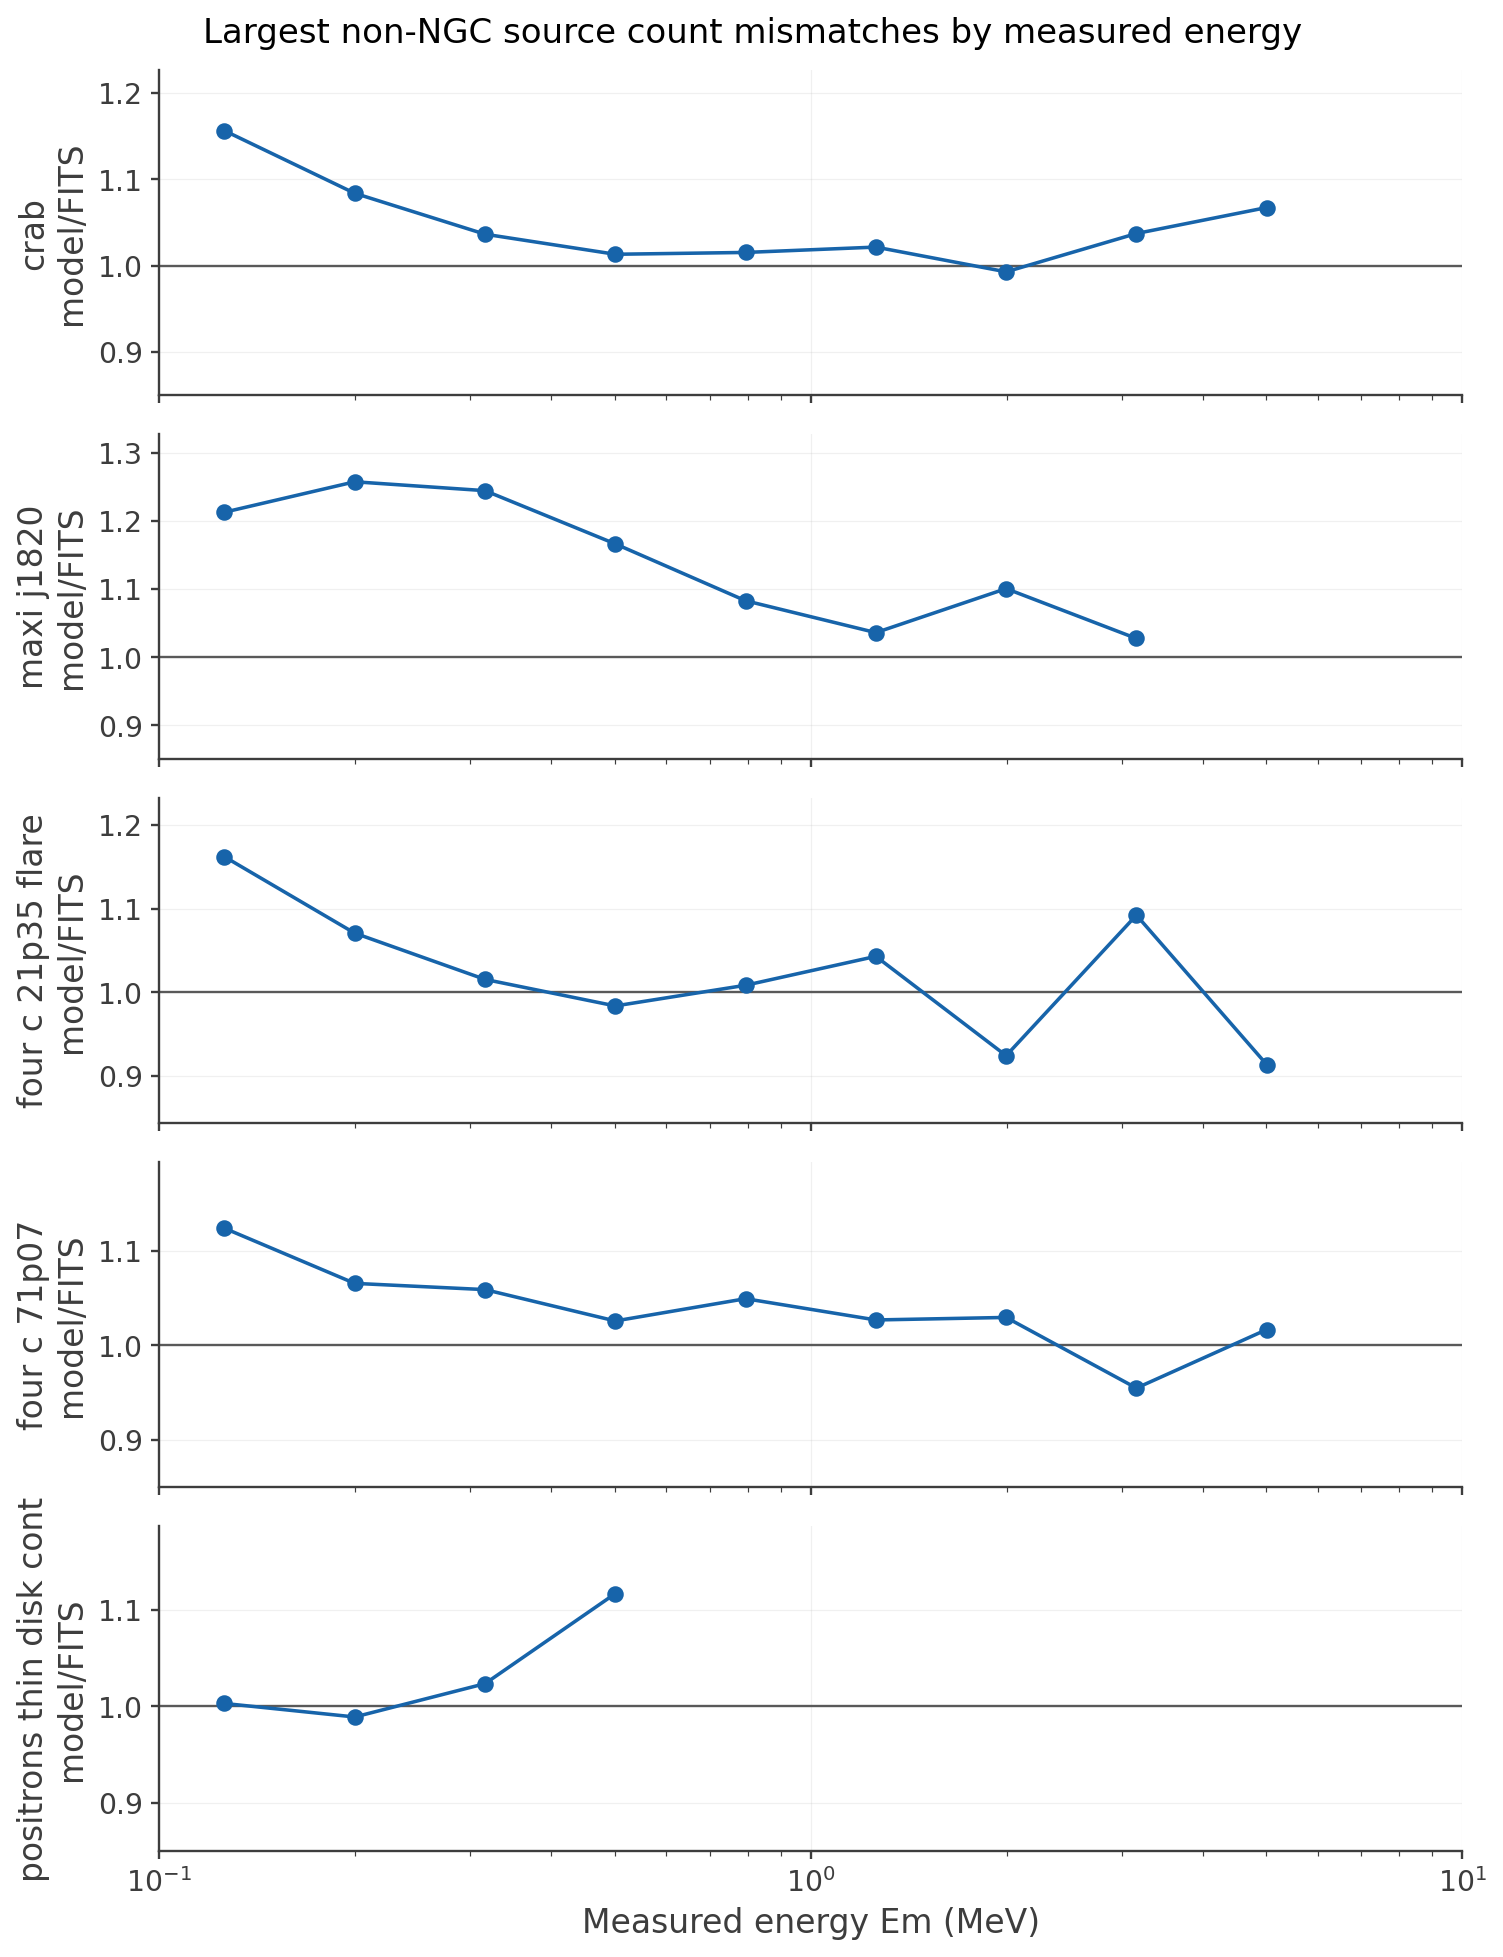

In [13]:
# Plot the five non-NGC sources with the largest absolute count discrepancies.
# Suppress ratios where the FITS bin contains fewer than 20 events.
focus_non_ngc = [s for s in absolute_rank["source"]
                 if s != "ngc4151" and fits_by_source[s].sum() >= 1000][:5]
fig, axes = plt.subplots(len(focus_non_ngc), 1, figsize=(9, 2.35 * len(focus_non_ngc)),
                         sharex=True)
for ax, source in zip(np.atleast_1d(axes), focus_non_ngc):
    observed = fits_by_source[source]
    predicted = model_by_source[source]
    ratio = np.divide(predicted, observed, out=np.full(10, np.nan), where=observed >= 20)
    ax.axhline(1, color="0.35", lw=1)
    ax.plot(centers, ratio, "o-", lw=1.5, color="#1764aa")
    ax.set_ylabel(source.replace("_", " ") + "\nmodel/FITS")
    ax.grid(alpha=0.25)
    valid = ratio[np.isfinite(ratio)]
    if valid.size:
        ax.set_ylim(min(0.85, valid.min() - 0.07), max(1.15, valid.max() + 0.07))
axes[-1].set_xscale("log")
axes[-1].set_xlim(0.1, 10)
axes[-1].set_xlabel("Measured energy Em (MeV)")
fig.suptitle("Largest non-NGC source count mismatches by measured energy")
fig.tight_layout()
figure_path = notebook_dir / "plots/DC4_source_catalog_detector_energy_source_ratios.png"
fig.savefig(figure_path, dpi=170)
plt.show()
print("Saved:", figure_path)


## Interpretation boundaries

- A source-by-source `model − FITS` difference can combine imperfect temporal/GTI modeling, response details, source spectrum representation, and source Monte Carlo fluctuations. This notebook measures the residual; it does not uniquely attribute it.
- The historical snapshot stores only the `Em` projection of the model prediction. To diagnose a mismatch in Compton angle or scattered direction, the generator must additionally save `Em × Phi` or full `Em × Phi × PsiChi` folded histograms. Those cannot be reconstructed from this snapshot.
- The original mock/source/background closure confirms that the measured data used in this audit are aligned. The fixed-catalog total is **not** a fitted NGC 4151 CPL result, and these residuals should not be interpreted as fit residuals.
- The source-ratio plot hides bins with fewer than 20 FITS counts; the CSV retains all bins. Small-count ratios fluctuate strongly, so inspect absolute counts alongside ratios.